In [1]:
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

No windowing system present. Using surfaceless platform
No config found!
No config found!


Available devices:
✅ (default) | NVIDIA A100-SXM4-40GB | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 16.0.6, 256 bits) | CPU | Vulkan | Mesa 24.0.0-devel (git-3ca1f35cbf) (LLVM 16.0.6)
❗ | NVIDIA A100-SXM4-40GB/PCIe/SSE2 | Unknown | OpenGL | 


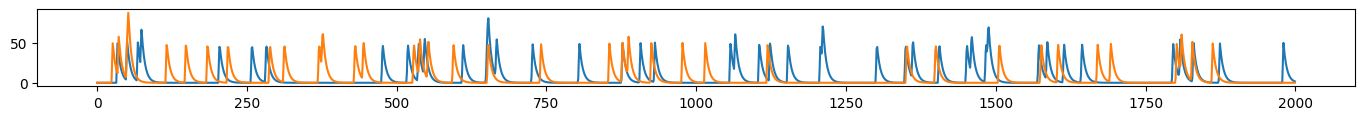

In [116]:
n_timepoints = 1_000
n_components = 2
interp_factor = 2

clean = np.zeros((n_components, n_timepoints * interp_factor))

x = 0
a = 0.7

b = 0

firing_prop = 0.05

spikes = list()

for i in range(n_components):
    spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

for c_ix in range(n_components):
    for i in range(2, n_timepoints):
        clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])

    x_ = np.arange(0, n_timepoints * interp_factor)
    xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
    clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

n_timepoints *= 2

fig = plt.figure(figsize=(17, 1))
for i in range(n_components):
    plt.plot(clean[i])

In [117]:
noise = 5

In [118]:
n_pixels = 3

series = list()

for i in range(n_components):
    for j in range(n_pixels):
        series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))

series = np.vstack(series)
n_pixels = n_pixels * n_components

<Axes: >

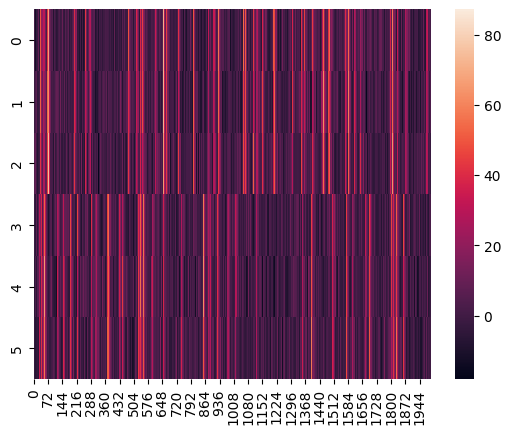

In [119]:
sns.heatmap(series)

In [120]:
series[-1] = np.random.normal(scale=noise, size=n_timepoints)
series[-1] -= series[-1].mean()

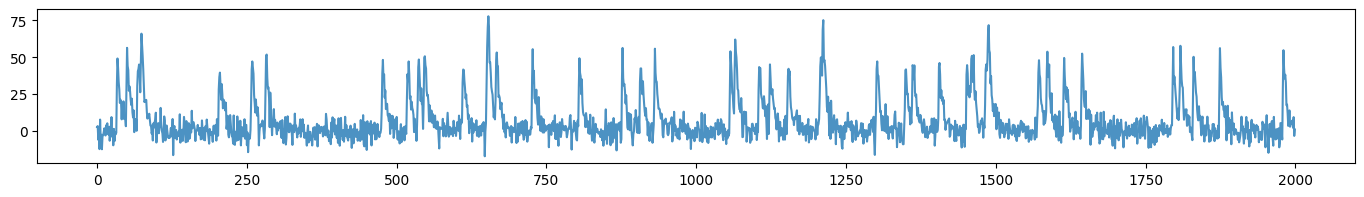

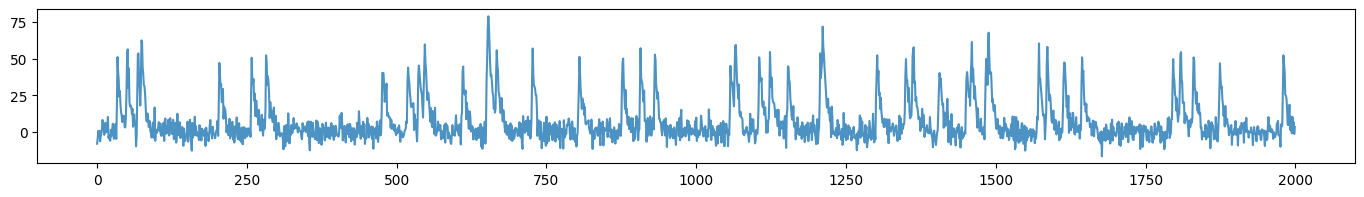

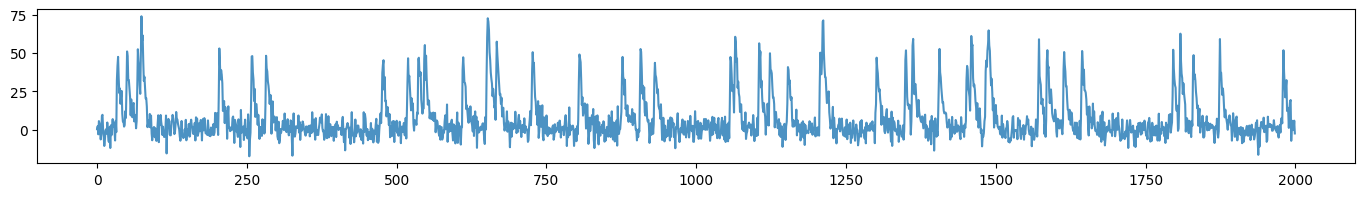

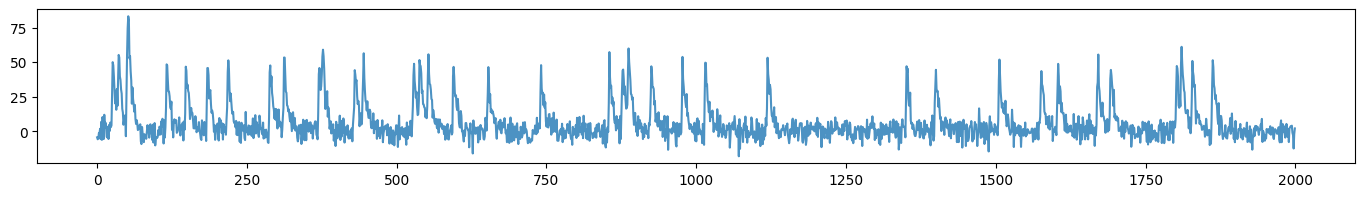

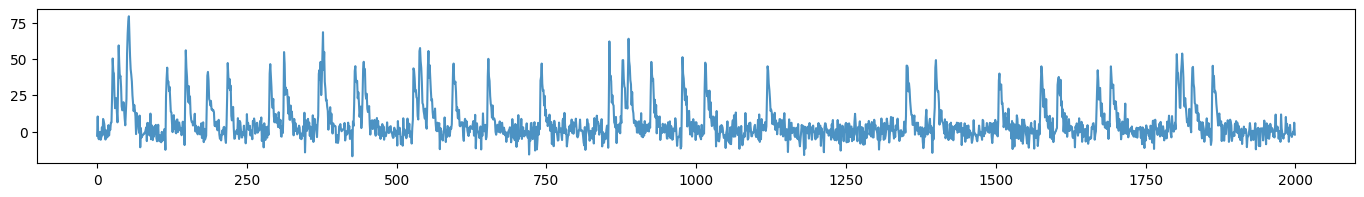

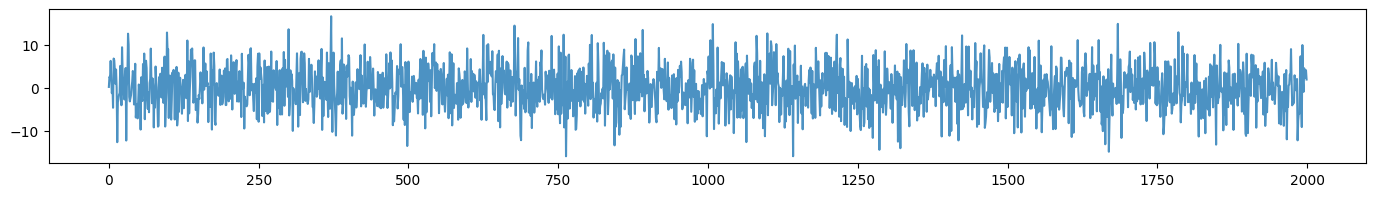

In [121]:
for i in range(n_pixels):
    fig = plt.figure(figsize=(17, 2))
    plt.plot(series[i], alpha=0.8)
    plt.show()

# plt.plot(clean, c="k", alpha=0.3)

In [122]:
series.mean(axis=1)

array([7.27845155, 7.31925448, 7.32888015, 6.52724356, 6.2592462 ,
       0.        ])

In [123]:
series.std(axis=1)

array([14.14722774, 14.15543916, 14.28377975, 13.17906026, 13.14835786,
        4.931214  ])

In [124]:
series.ptp(axis=1)

array([ 94.85233917,  95.55819522,  91.50296057, 101.11699857,
        96.42389537,  32.38025877])

In [125]:
from scipy import linalg

In [126]:
import seaborn as sns

In [127]:
center = 100
w = 16

Ys = list()
Ps = list()
Fs = list()

# fig, axs = plt.subplots(3, n_pixels, figsize=(15, 10))

for i in range(n_pixels):
    y = linalg.hankel(series[i, :w], series[i, w:])
    p = np.flipud(y[:int(w / 2)])
    f = y[int(w / 2):]

    Ys.append(y)
    Ps.append(p)
    Fs.append(f)
        
    # sns.heatmap(y, ax=axs[0, i])
    # axs[0, i].set_title(f"$Y_{i}$")

    # sns.heatmap(p, ax=axs[1, i])
    # axs[1, i].set_title(f"$P_{i}$")

    # sns.heatmap(f, ax=axs[2, i])
    # axs[2, i].set_title(f"$F_{i}$")

# plt.tight_layout()

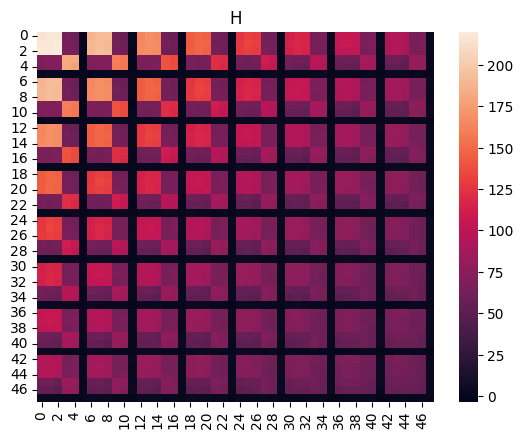

In [128]:
P_F_shape = (int(w / 2) * n_pixels, n_timepoints - w)

P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

for i in range(n_pixels):
    P[i::n_pixels] = Ps[i]
    F[i::n_pixels] = Fs[i]

# fig, axs = plt.subplots(1, 2, figsize=(15, 5))

# sns.heatmap(P, ax=axs[0])
# axs[0].set_title(f"$P$")

# sns.heatmap(F, ax=axs[1])
# axs[1].set_title(f"$F$")
# plt.show()

H = (F @ P.T) / P.shape[1]

sns.heatmap(H)#, annot=True, fmt="0.1f")
plt.title("H")
plt.show()

In [129]:
from itertools import product

In [130]:
list(product(*[range(0, int(w / 2) + n_pixels + 1, n_pixels)]*2))

[(0, 0), (0, 6), (0, 12), (6, 0), (6, 6), (6, 12), (12, 0), (12, 6), (12, 12)]

In [131]:
Hp = np.zeros((int(w / 2)**2, n_pixels**2))

for row_ix, (block_i, block_j) in enumerate(product(*[range(0, int(w / 2) * n_pixels, n_pixels)]*2)):
    Hp[row_ix] = H.T[block_i:block_i + n_pixels, block_j:block_j + n_pixels].ravel()

<Axes: >

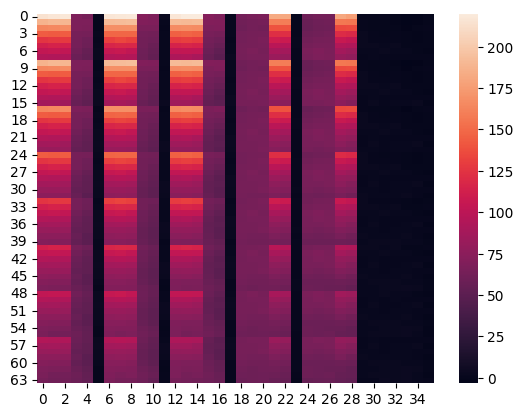

In [132]:
sns.heatmap(Hp)#, annot=True, fmt="0.1f")

In [133]:
u, s, v = linalg.svd(Hp)

Text(0.5, 1.0, 'V')

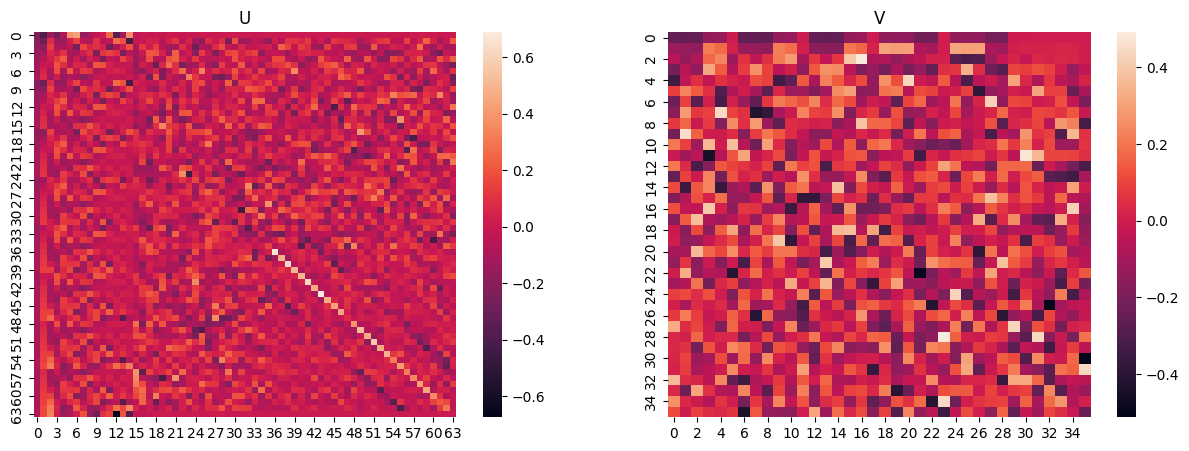

In [134]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(u, ax=axs[0])
axs[0].set_title("U")
sns.heatmap(v, ax=axs[1])
axs[1].set_title("V")

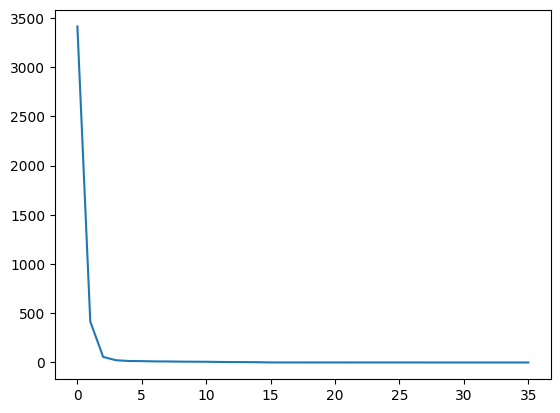

In [135]:
plt.plot(s)

Text(0.5, 1.0, '$V^r$')

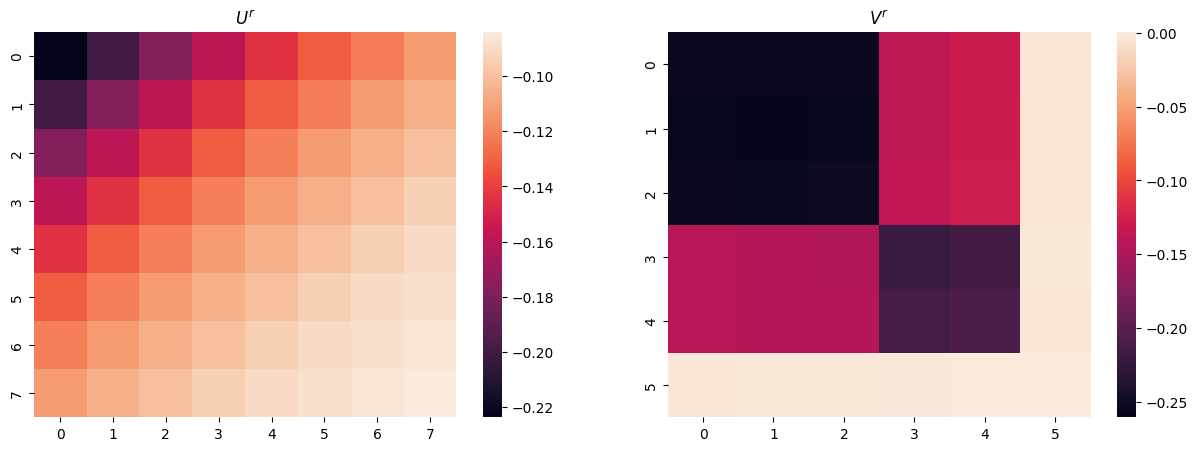

In [136]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
u_r = u[:, 0].reshape(int(w / 2), int(w / 2))
sns.heatmap(u_r, ax=axs[0])
axs[0].set_title("$U^r$")

v_r = v[0].reshape(n_pixels, n_pixels)
sns.heatmap(v_r, ax=axs[1])
axs[1].set_title("$V^r$")

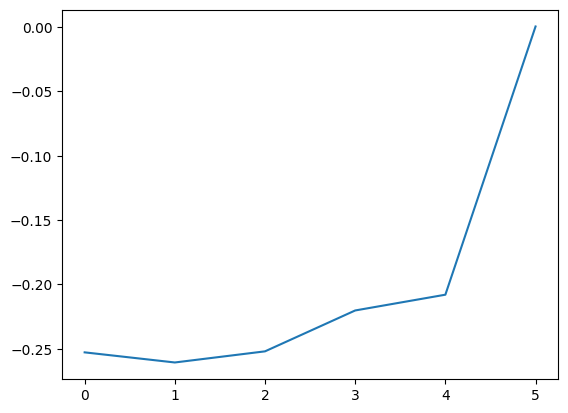

In [137]:
plt.plot(v_r.diagonal())

In [138]:
u_s, s_s, v_s = linalg.svd(v_r)

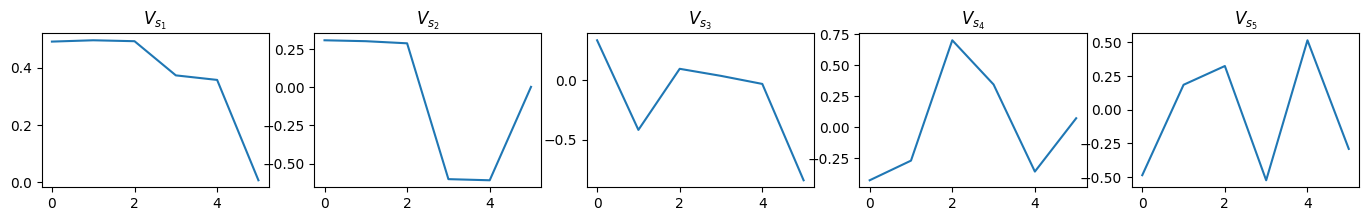

In [139]:
fig, axs = plt.subplots(1, 5, figsize=(17, 2))

for i in range(5):
    axs[i].plot(v_s[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

In [140]:
B = np.abs(v_r + v_r.T) / 2

<Axes: >

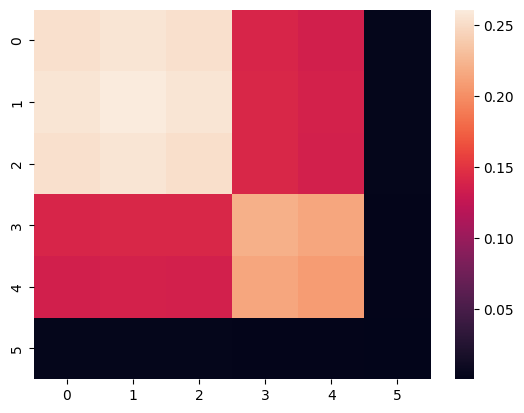

In [141]:
sns.heatmap(B)

In [142]:
def laplacian(graph, normed, degree_axis):
    """Returns L, D"""
    dtype = graph.dtype
    graph = graph.copy()

    np.fill_diagonal(graph, 0)
    w = graph.sum(axis=degree_axis)
    if normed:
        isolated_node_mask = (w == 0)
        w = np.where(isolated_node_mask, 1, np.sqrt(w))
        graph /= w
        graph /= w[:, np.newaxis]
        graph *= -1
        
        d = 1 - isolated_node_mask
        step = len(d) + 1
        graph.flat[::step] = d
    else:
        graph *= -1
        d = w
        step = len(d) + 1
        graph.flat[::step] = d

    return graph.astype(dtype, copy=False), w.astype(dtype, copy=False)

In [143]:
from scipy.sparse import csgraph

In [144]:
L_, D_ = csgraph.laplacian(B, normed=True, return_diag=True)

In [145]:
L, D = laplacian(B, normed=True, degree_axis=0)

<Axes: >

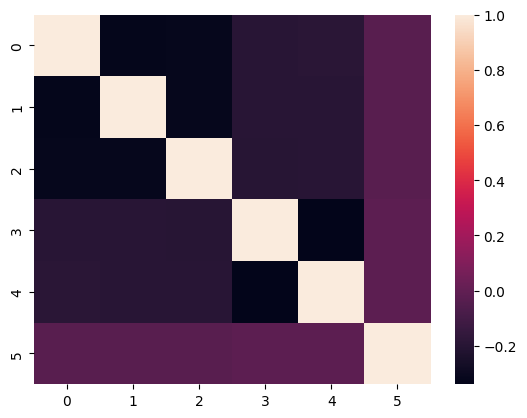

In [146]:
sns.heatmap(L)

In [147]:
np.all(L_ == L) and np.all(D_ == D)

True

In [167]:
evals, evecs = np.linalg.eigh(B)

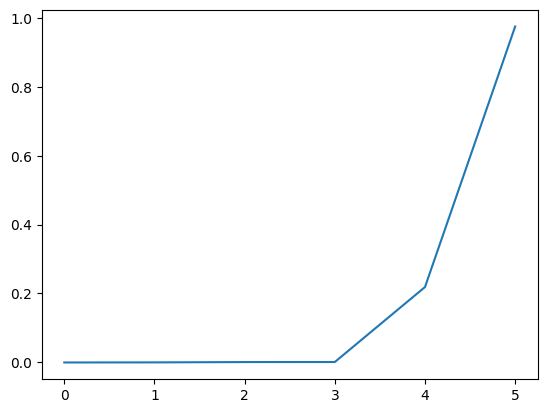

In [168]:
plt.plot(evals)

<Axes: >

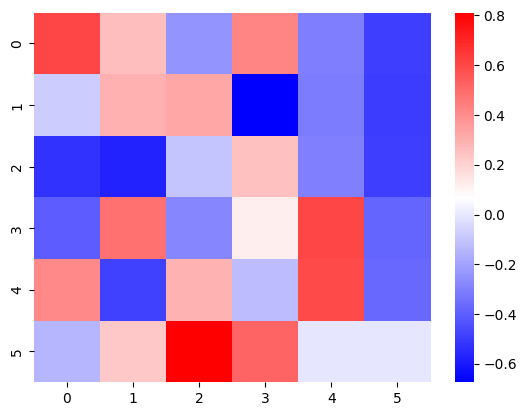

In [169]:
sns.heatmap(evecs, cmap="bwr")

In [170]:
k = 2

In [171]:
from scipy.linalg import qr, svd

In [172]:
vk = evecs[:, -k:]

In [173]:
vk.shape

(6, 2)

<Axes: >

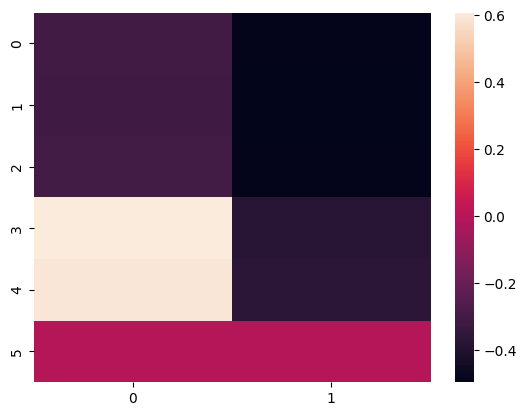

In [174]:
sns.heatmap(vk)

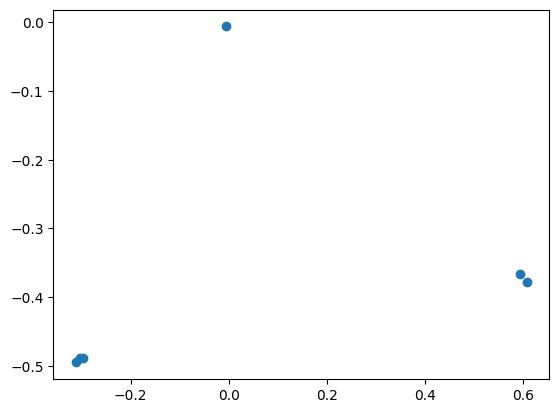

In [187]:
plt.scatter(vk[:, 0], vk[:, 1])

In [189]:
vk.T

array([[-0.30296987, -0.31193827, -0.29727972,  0.60781516,  0.59419287,
        -0.00491083],
       [-0.48854202, -0.49502   , -0.48865903, -0.37837608, -0.36645458,
        -0.00606844]])

In [115]:
fig = fpl.Figure(cameras="3d", controller_types="orbit")

fig[0, 0].add_scatter(vk, sizes=10)
fig[0, 0].axes.grids.visible = False
fig[0, 0].axes.x.line.material.color = "r"
fig[0, 0].axes.y.line.material.color = "g"
fig[0, 0].axes.z.line.material.color = "b"

fig.show()

RFBOutputContext()

/mnt/home/kkolar/repos/pygfx/pygfx/objects/_ruler.py:245: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/mnt/home/kkolar/repos/pygfx/pygfx/objects/_ruler.py:245: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/mnt/home/kkolar/repos/pygfx/pygfx/objects/_ruler.py:257: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size
/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [190]:
vk.shape

(6, 2)

In [191]:
Q, R, pivot = qr(vk.T, pivoting=True)

In [197]:
np.linalg.norm(vk.T, axis=0, ord=2)

array([0.57486002, 0.58510707, 0.57198154, 0.71596629, 0.69810753,
       0.00780655])

In [198]:
vk.T.shape

(2, 6)

<Axes: >

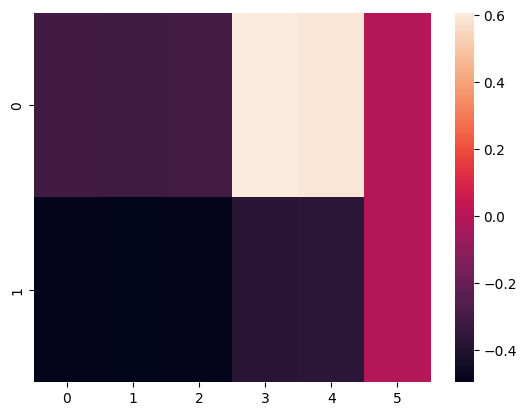

In [199]:
sns.heatmap(vk.T)

# Must normalize rows of vk here

<Axes: >

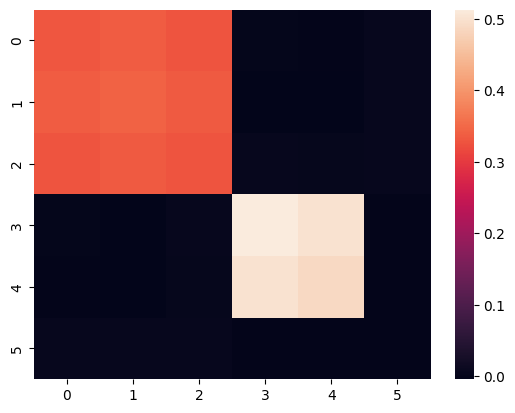

In [211]:
sns.heatmap(vk @ vk.T)

In [192]:
pivot

array([3, 1, 2, 0, 4, 5], dtype=int32)

In [215]:
vk

array([[-0.30296987, -0.48854202],
       [-0.31193827, -0.49502   ],
       [-0.29727972, -0.48865903],
       [ 0.60781516, -0.37837608],
       [ 0.59419287, -0.36645458],
       [-0.00491083, -0.00606844]])

In [216]:
vk.shape

(6, 2)

<Axes: >

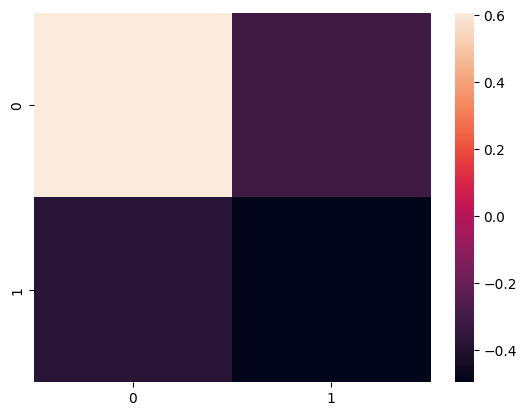

In [238]:
sns.heatmap(vk.T[:, pivot[:k]])

# need to normalize vk first

In [239]:
u, s, vT = svd(vk.T[:, pivot[:k]], full_matrices=False)

In [240]:
u.shape, v.shape

((2, 2), (2, 2))

In [241]:
U = u @ v
U[:, 0] @ U[:, 1]

-1.3638117261857062e-16

<Axes: >

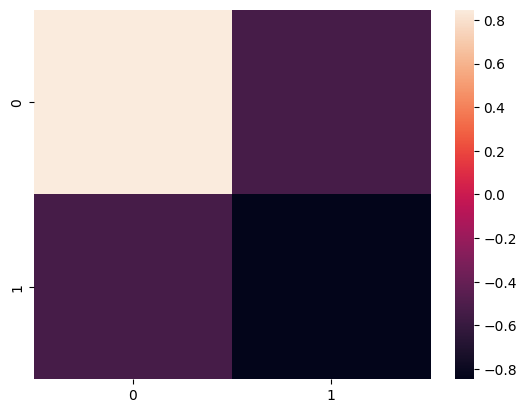

In [242]:
sns.heatmap(U)

In [245]:
U

array([[ 0.84763803, -0.53057494],
       [-0.53057494, -0.84763803]])

In [249]:
fig = fpl.Figure()

fig[0, 0].add_scatter(U, sizes=10)
fig[0, 0].axes.follow = False

fig.show()

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

# TODO

1. More components
2. varying numbers of pixels per components, 7, 4, 2
3. pixels that belong to multiple components


In [252]:
fig[0, 0].add_scatter(vk, colors="r", sizes=10)

ScatterGraphic @ 0x1554ced44fd0

In [254]:
transformed = U.T @ vk.T

In [255]:
transformed.shape

(2, 6)

In [257]:
fig[0, 0].add_scatter(transformed.T, colors="b", sizes=10)

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


ScatterGraphic @ 0x1554d40b54d0

In [258]:
transformed.T

array([[ 0.00239937,  0.57485502],
       [-0.00176553,  0.58510441],
       [ 0.00728464,  0.57193515],
       [ 0.71596411, -0.00176553],
       [ 0.69809209, -0.00464301],
       [-0.00094284,  0.0077494 ]])

In [62]:
n_clusters = 5

In [63]:
u, s, v = svd(evecs[:, :n_clusters][pivot[:n_clusters], :].T)

y = abs(np.dot(evecs, np.dot(u, v.conj()))).argmax(axis=1)

ValueError: shapes (12,12) and (5,5) not aligned: 12 (dim 1) != 5 (dim 0)

In [26]:
v_s[0]

array([0.7150654 , 0.69854892, 0.02666227])

In [27]:
filt = np.kron(v_s[0], v_t[0])

In [28]:
filt.shape

(9,)

In [29]:
P.shape

(9, 1994)

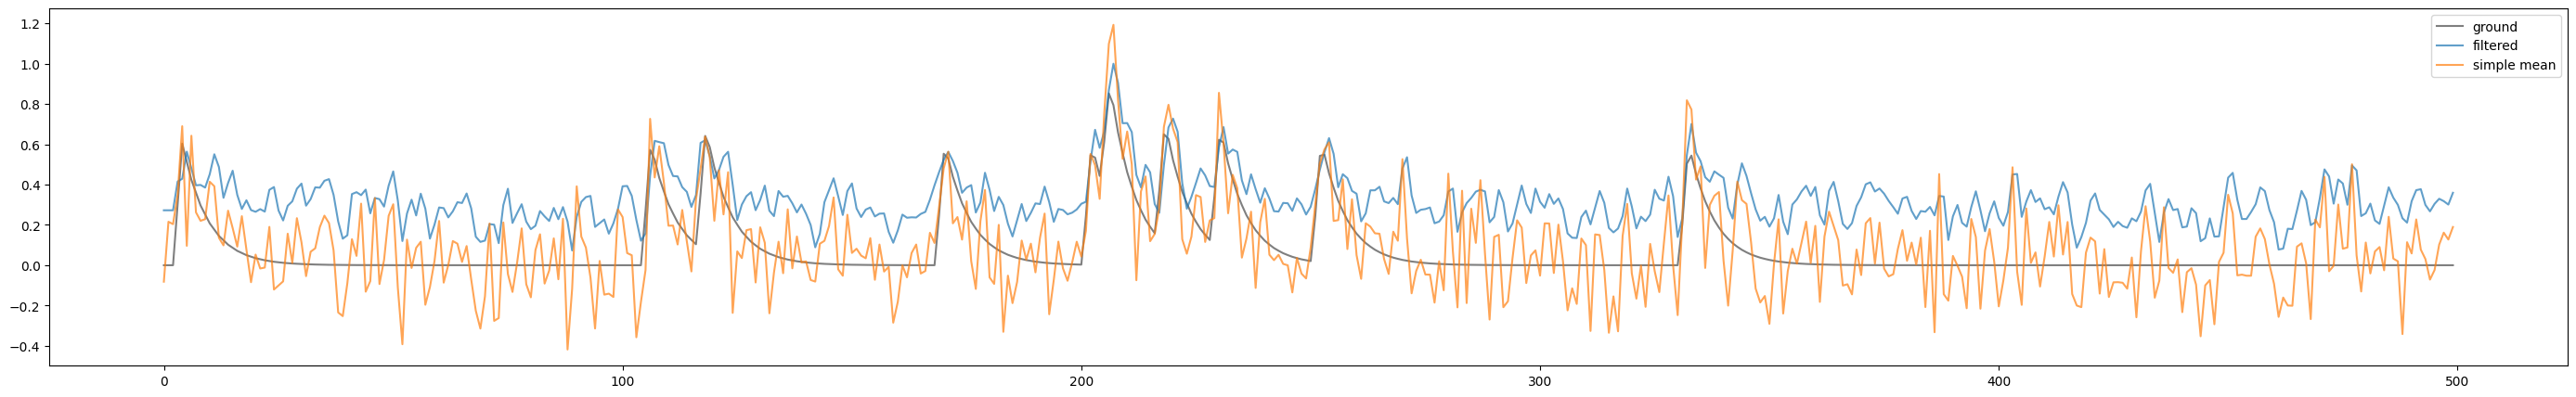

In [30]:
filtered = np.zeros(shape=(n_timepoints - int(w / 2)))
filtered[int(w / 2):] = filt @ P


filtered -= filtered.min()
filtered /= filtered.max()

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[0, indices] / clean.max(), label="ground", alpha=0.5, c="k")
plt.plot(filtered[indices], label="filtered", alpha=0.7)
plt.plot(series[:-1].mean(axis=0)[indices] / clean.max(), alpha=0.7, label="simple mean")
plt.legend()
plt.show()